# 03 · APS Failure at Scania Trucks — Exploratory Data Analysis

**Goal:** understand the 170 anonymized operational features, the missing-value and sentinel
patterns, and the class structure. **All analysis here uses the official training set
only**; the test set is loaded just to confirm its shape and class balance.

Reminder (dataset documentation): the negative class is *trucks whose failures were in
components unrelated to the APS*. The task is attributing a failure to the APS, not
telling failed trucks from healthy ones.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import config as C
from src import visualization as V
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 40)
FIG = C.FIGURES_DIR
from src.data_loader import load_aps
from sklearn.metrics import roc_auc_score
tr, te = load_aps()
X, y = tr.drop(columns=C.APS_TARGET), tr[C.APS_TARGET]
FIGD = FIG / 'aps'

## 1. Dimensions, structure and data types

In [2]:
print("train:", tr.shape, "| test:", te.shape)
print("dtypes:", X.dtypes.value_counts().to_dict())
prefix = pd.Series([c.split('_')[0] for c in X.columns], index=X.columns)
groups = prefix.value_counts()
hist_groups = groups[groups > 1]
print(f"{len(hist_groups)} histogram groups x 10 bins = {hist_groups.sum()} features; {(groups==1).sum()} single counters")
print("histogram groups:", ", ".join(hist_groups.index))

train: (60000, 171) | test: (16000, 171)
dtypes: {dtype('float64'): 169, dtype('int64'): 1}
7 histogram groups x 10 bins = 70 features; 100 single counters
histogram groups: ag, ay, az, ba, cn, cs, ee


## 2. Target distribution and class imbalance

train: 1000 pos / 59000 neg  (1.67%); ratio 59:1
test: 375 pos / 15625 neg  (2.34%); ratio 42:1


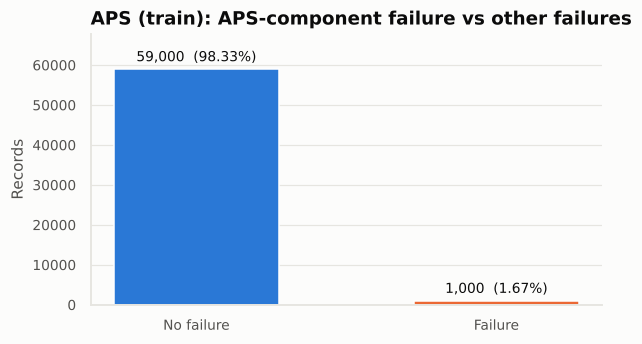

In [3]:
for name, d in [("train", tr), ("test", te)]:
    print(f"{name}: {int(d['class'].sum())} pos / {int((d['class']==0).sum())} neg  ({d['class'].mean():.2%}); ratio {(d['class']==0).sum()/d['class'].sum():.0f}:1")
V.save(V.target_distribution(y, "APS (train): APS-component failure vs other failures"), FIGD / "01_target_distribution.png"); plt.show()

## 3. Missing values

missing cells: 8.33% | rows with any missing: 99.0% | complete rows: 591


,0%,0-1%,1-5%,5-20%,20-50%,50-70%,>70%
columns,1,9,118,18,16,1,7


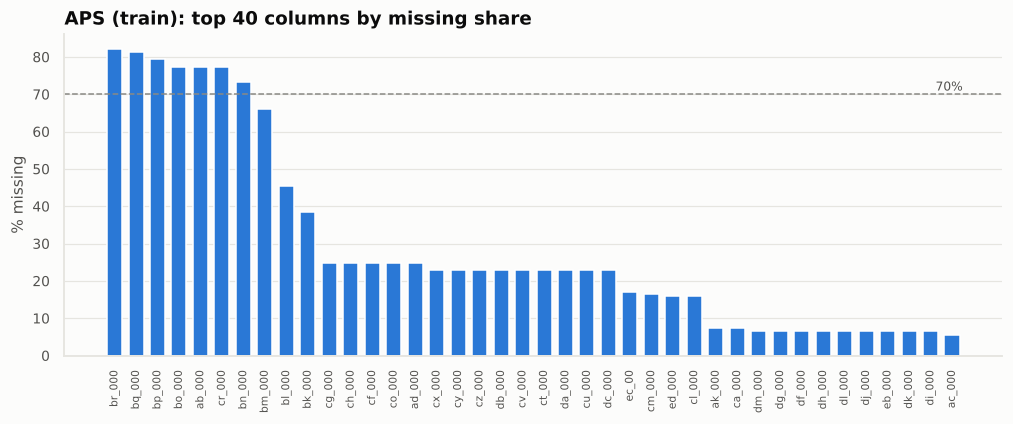

In [4]:
miss = X.isna().mean()
print(f"missing cells: {X.isna().values.mean():.2%} | rows with any missing: {X.isna().any(axis=1).mean():.1%} | complete rows: {int((~X.isna().any(axis=1)).sum())}")
bands = pd.cut(miss, [-0.001, 0, .01, .05, .2, .5, .7, 1.0], labels=["0%","0-1%","1-5%","5-20%","20-50%","50-70%",">70%"])
display(bands.value_counts().sort_index().rename("columns").to_frame().T)
V.save(V.missing_bar(miss, "APS (train): top 40 columns by missing share"), FIGD / "02_missing_by_column.png"); plt.show()

,feature,missing_%,fail_rate_if_missing_%,fail_rate_if_present_%
11,br_000,82.1,0.18,8.48
10,bq_000,81.2,0.18,8.10
9,bp_000,79.6,0.17,7.48
21,cr_000,77.2,1.66,1.68
8,bo_000,77.2,0.17,6.75
0,ab_000,77.2,1.66,1.68
7,bn_000,73.3,0.17,5.79
6,bm_000,65.9,0.18,4.54
5,bl_000,45.5,0.25,2.85
4,bk_000,38.4,0.28,2.53


missing values per row - mean by class: {0: 13.9, 1: 29.2} | median: {0: 8.0, 1: 20.5}
single-feature ROC-AUC of row missing-count: 0.677


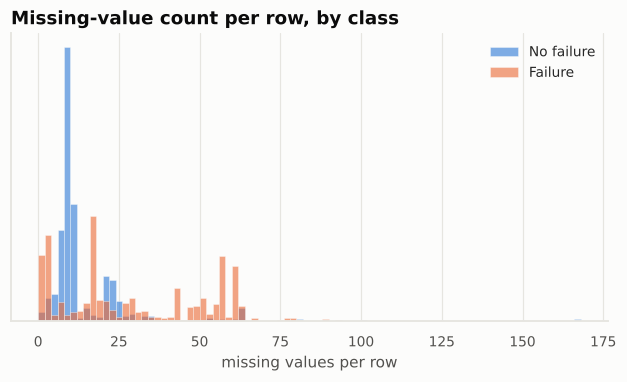

In [5]:
# Is missingness informative? failure rate when a column is missing vs present
rows = []
for c in miss[miss > 0.05].index:
    m = X[c].isna()
    rows.append({"feature": c, "missing_%": round(m.mean()*100,1),
                 "fail_rate_if_missing_%": round(y[m].mean()*100,2), "fail_rate_if_present_%": round(y[~m].mean()*100,2)})
mi = pd.DataFrame(rows).sort_values("missing_%", ascending=False); display(mi.head(15))
nm = X.isna().sum(axis=1)
print("missing values per row - mean by class:", nm.groupby(y).mean().round(1).to_dict(), "| median:", nm.groupby(y).median().to_dict())
print("single-feature ROC-AUC of row missing-count:", round(roc_auc_score(y, nm), 3))
fig, ax = plt.subplots(figsize=(7,3.4))
for k in [0,1]: ax.hist(nm[y==k], bins=range(0, int(nm.max())+2, 2), density=True, alpha=.6, color=V.CLASS_COLORS[k], label=V.CLASS_NAMES[k], edgecolor=V.SURFACE, linewidth=.4)
ax.set(xlabel="missing values per row", title="Missing-value count per row, by class"); ax.set_yticks([]); ax.legend()
V.save(fig, FIGD / "03_missing_per_row.png"); plt.show()

## 4. Sentinel values (−1 and others)

In [6]:
print("cells equal to -1:", int((X == -1).sum().sum()), "| columns with any negative value:", int((X < 0).any().sum()))
hi = (X >= 2.13e9) & (X < 2**31)
print("columns with values in [2.13e9, 2^31):", hi.sum()[hi.sum() > 0].to_dict())
ac = X[C.APS_SENTINEL_COL]
print("ac_000 most frequent values:"); print(ac.value_counts().head(6).to_string())
s = ac >= C.APS_SENTINEL_MIN
print(f"sentinel share {s.mean():.2%}; failure rate | sentinel {y[s].mean():.2%} vs non-sentinel {y[~s & ac.notna()].mean():.2%} vs ac_000 missing {y[ac.isna()].mean():.2%}")
print("2130706432 == 0x7F000000:", 2130706432 == 0x7F000000)
print("next-largest ac_000 value below the sentinel band:", ac[ac < 2.13e9].max())

cells equal to -1: 0 | columns with any negative value: 0
columns with values in [2.13e9, 2^31): {'ac_000': 9468}
ac_000 most frequent values:
ac_000
0.000000e+00    8752
2.130706e+09    6188
2.130706e+09    1227
4.000000e+00     768
8.000000e+00     762
2.000000e+00     756
sentinel share 15.78%; failure rate | sentinel 0.16% vs non-sentinel 1.11% vs ac_000 missing 13.85%
2130706432 == 0x7F000000: True
next-largest ac_000 value below the sentinel band: 265766.0


## 5. Constant columns and duplicates

In [7]:
nun = X.nunique(dropna=True)
print("constant columns:", list(nun[nun <= 1].index), "| duplicate rows:", int(tr.duplicated().sum()), "| duplicate feature rows:", int(X.duplicated().sum()))

constant columns: ['cd_000'] | duplicate rows: 0 | duplicate feature rows: 0


## 6. Statistical summary and skewness

In [8]:
d = X.describe().T
d["skew"] = X.skew()
display(d.sort_values("skew", ascending=False).head(8).round(1))
print("median |skew| across features:", round(X.skew().abs().median(), 1), "| features with |skew| > 10:", int((X.skew().abs() > 10).sum()))
print("share of zero values (median across features):", f"{(X == 0).mean().median():.1%}")

,count,mean,std,min,25%,50%,75%,max,skew
cs_009,59331.0,779.2,184358.5,0.0,0.0,0.0,0.0,4.490299e+07,243.5
cf_000,45139.0,190221.8,40404413.2,0.0,0.0,2.0,2.0,8.584298e+09,212.5
co_000,45139.0,190515.6,40404411.9,0.0,0.0,8.0,72.0,8.584298e+09,212.5
ad_000,45139.0,190620.6,40404411.4,0.0,24.0,126.0,430.0,8.584298e+09,212.5
dh_000,55992.0,4707.1,560279.9,0.0,0.0,0.0,0.0,1.247009e+08,202.9
az_009,59329.0,42.1,3256.6,0.0,0.0,0.0,0.0,6.661480e+05,163.6
ay_009,59329.0,1162.6,97960.8,0.0,0.0,0.0,0.0,1.882466e+07,159.1
ag_000,59329.0,221.6,20478.5,0.0,0.0,0.0,0.0,3.376892e+06,153.4


median |skew| across features: 17.5 | features with |skew| > 10: 114
share of zero values (median across features): 10.0%


## 7. Feature relationships with the label

Features are anonymized, so I rank them by **single-feature ROC-AUC** (each feature on its
own, missing values filled with the training median). This is a screening statistic only:
it measures association, not causation.

,single-feature AUC,missing %
ci_000,0.969,0.6
ck_000,0.968,0.6
aa_000,0.967,0.0
bt_000,0.965,0.3
bj_000,0.946,1.0
ap_000,0.942,1.1
bb_000,0.942,1.1
dn_000,0.941,1.2
bv_000,0.941,1.2
cq_000,0.941,1.2


features with |AUC-0.5| > 0.4: 34, > 0.3: 65


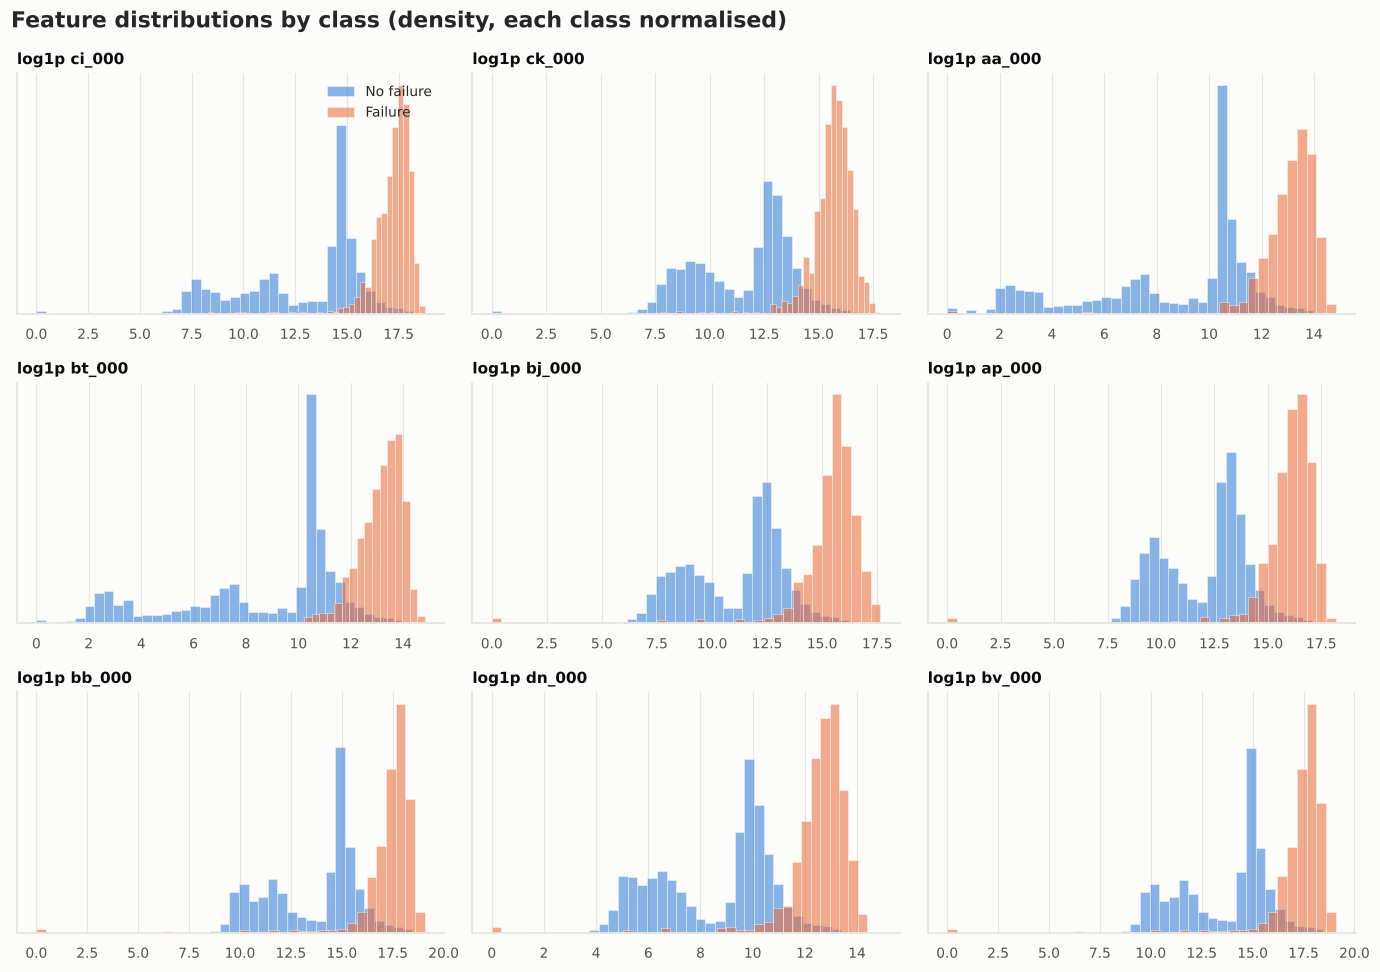

In [9]:
Xm = X.fillna(X.median())
auc = Xm.apply(lambda c: roc_auc_score(y, c)).rename("auc")
rank = (auc - 0.5).abs().sort_values(ascending=False)
top = rank.index[:20]
display(pd.DataFrame({"single-feature AUC": auc[top].round(3), "missing %": (miss[top]*100).round(1)}).head(12))
print(f"features with |AUC-0.5| > 0.4: {int((rank>0.4).sum())}, > 0.3: {int((rank>0.3).sum())}")
V.save(V.class_conditional_hist(tr, list(top[:9]), C.APS_TARGET, log_x=True), FIGD / "04_top_feature_distributions.png"); plt.show()

## 8. Correlation analysis

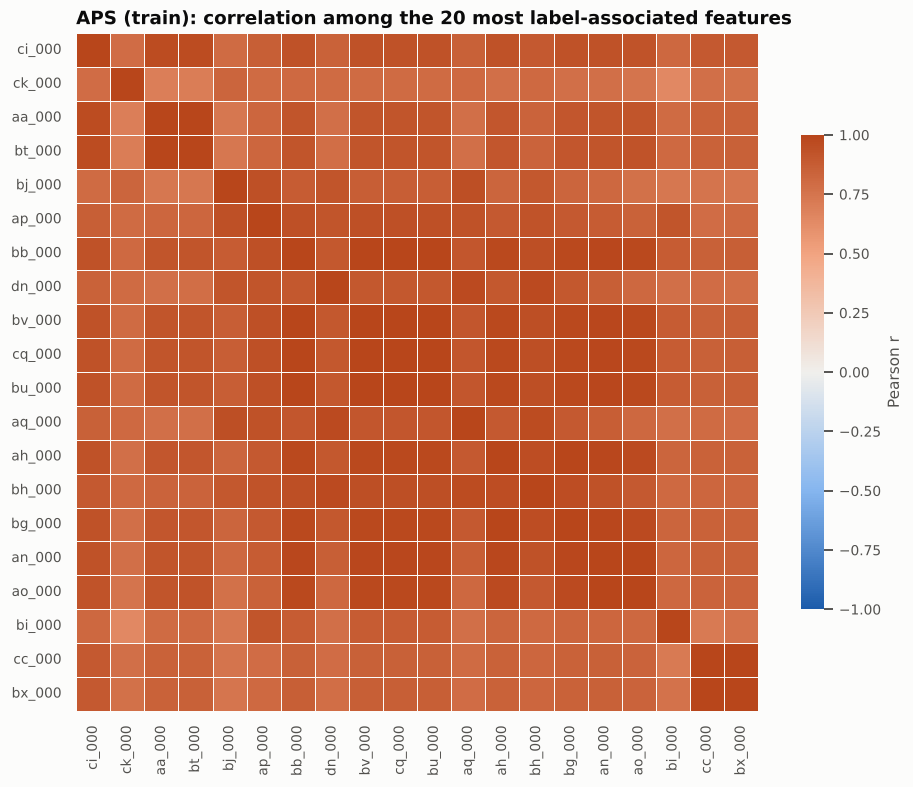

feature pairs: 14,365 | |r|>0.9: 137 | |r|>0.99: 14


In [10]:
corr = X[top].corr()
V.save(V.correlation_heatmap(X[top], "APS (train): correlation among the 20 most label-associated features", annot=False, figsize=(10,8)), FIGD / "05_correlation_top20.png"); plt.show()
full = X.corr().abs(); iu = np.triu_indices_from(full, 1); vals = full.values[iu]
print(f"feature pairs: {len(vals):,} | |r|>0.9: {(vals>0.9).sum()} | |r|>0.99: {(vals>0.99).sum()}")

## 9. Outlier detection

IQR outliers on log1p scale (features with IQR>0): median share 0.2%, max 15.8%
failure rate among rows with >=10 outlying features: 3.77% (n=1513) vs overall 1.67%


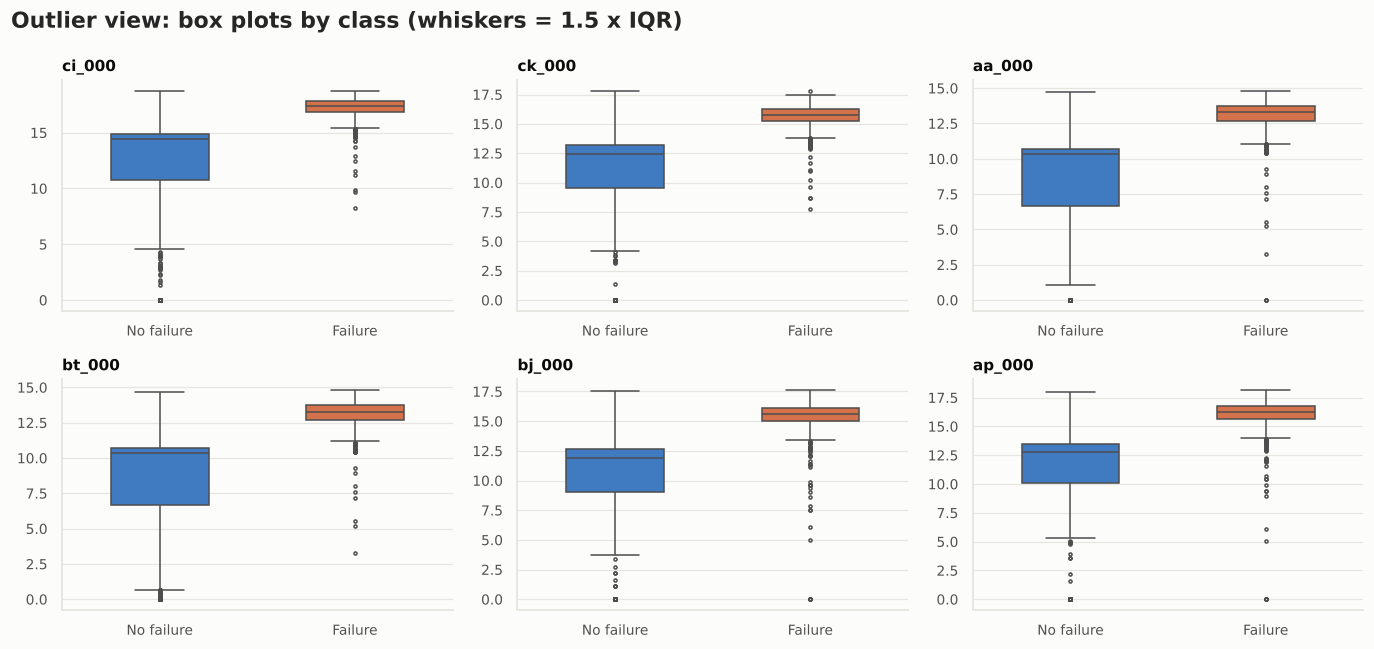

In [11]:
L = np.log1p(X)
q1, q3 = L.quantile(.25), L.quantile(.75); iqr = q3 - q1
outl = ((L < q1 - 1.5*iqr) | (L > q3 + 1.5*iqr)) & (iqr > 0)
share = outl.mean()
print(f"IQR outliers on log1p scale (features with IQR>0): median share {share[iqr>0].median():.1%}, max {share.max():.1%}")
rows_out = outl.sum(axis=1)
print("failure rate among rows with >=10 outlying features:", f"{y[rows_out>=10].mean():.2%}", f"(n={int((rows_out>=10).sum())})", "vs overall", f"{y.mean():.2%}")
V.save(V.boxplots(L.assign(**{C.APS_TARGET: y}), list(top[:6]), C.APS_TARGET), FIGD / "06_outlier_boxplots_log.png"); plt.show()

## 10. Histogram feature profiles

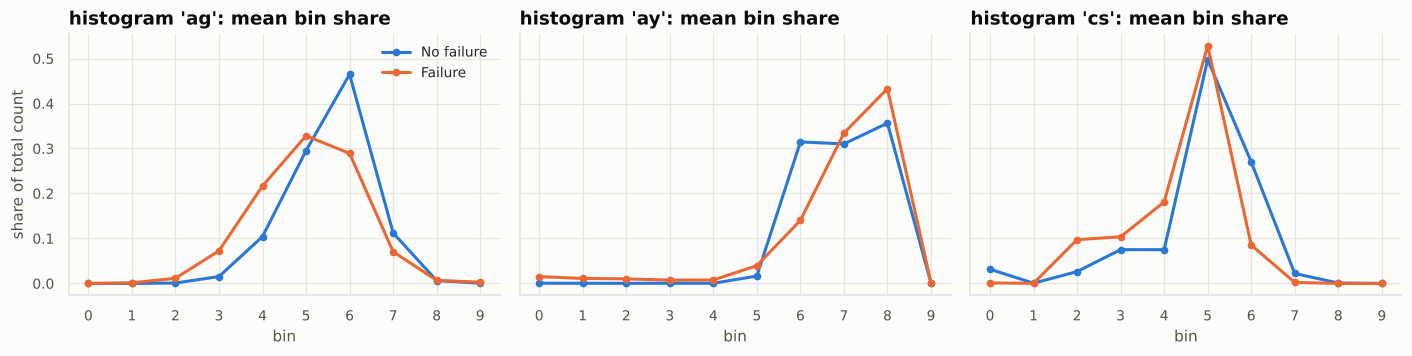

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4), sharey=True)
for ax, g in zip(axes, ["ag", "ay", "cs"]):
    cols = [c for c in X.columns if c.startswith(g + "_")]
    shares = X[cols].div(X[cols].sum(axis=1), axis=0)
    for k in [0, 1]:
        ax.plot(range(10), shares[y == k].mean().values, marker="o", ms=4, color=V.CLASS_COLORS[k], label=V.CLASS_NAMES[k])
    ax.set(title=f"histogram '{g}': mean bin share", xlabel="bin"); ax.set_xticks(range(10))
axes[0].set_ylabel("share of total count"); axes[0].legend()
fig.tight_layout(); V.save(fig, FIGD / "07_histogram_profiles.png"); plt.show()

## 11. EDA summary → preprocessing decisions

- **Structure:** 170 numeric features: 100 counters + 7 histograms × 10 bins. Train 60,000
  (1.67% positive), test 16,000 (2.34% positive). The official split is preserved.
- **No −1 sentinels** anywhere and no negative values. Missing values are `"na"` only: 8.3% of
  cells, 99% of rows. Only 591 training rows are complete, so dropping rows is not an option →
  **impute** (median; alternatives compared in notebook 04).
- **Missingness is informative:** positives average 29 missing values per row vs 14 for
  negatives (single-feature AUC 0.68). Rows missing `ac_000` fail at 13.9%, and the
  `bm–br` block fails at only 0.17–0.18% when missing → add a **per-row missing count** and keep
  heavily-missing columns (dropping them is evaluated, not assumed).
- **`ac_000` sentinel:** 15.8% of values sit at 0x7F000000 (2130706432) and two neighbors,
  far above the next real value (265,766). Failure rate is 0.16% there → **flag it, then treat the
  raw value as missing**.
- **`cd_000` is constant** → dropped (learned from training data inside the pipeline).
- **Extreme skew** (median |skew| 17.5) → **log1p** before scaling for LR and KNN.
- **Strong univariate signal and redundancy:** many single features reach AUC ≈ 0.97, and 137
  feature pairs have |r| > 0.9, so models with built-in feature selection (trees, regularized LR)
  are appropriate.
- **Outliers** (IQR on the log scale) are rare per feature, but rows with many outlying features
  fail at 2× the base rate → kept.